# Multi-class model feature importance

We extract the coefficients from the multi-class logistic regression model (`model_all_hearts_final_multiclass`), which predicts Healthy, DCM, or ICM.
A multinomial model learns one coefficient per feature **per class**, so each class gets its own importance profile.
A positive coefficient means a higher feature value makes a cell more likely to be that class, and a negative coefficient means less likely.
Features are normalized before training, so we use the absolute coefficient as the feature importance.

We generate three figures:

1. **Measurement type x channel heatmap**: the max |coefficient| per compartment and measurement type (rows) and channel (columns) for each class.
2. **Correlation channel pair heatmap**: the max |coefficient| across all correlation features (any compartment or correlation measurement) for each pair of channels.
3. **Top features per class**: the features with the largest |coefficient| for each class, colored by direction.

## Import libraries and helper functions

In [1]:
import os
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import load
from matplotlib.colors import LinearSegmentedColormap


def parse_feature_names(feature_names: np.ndarray) -> pd.DataFrame:
    """
    Split CellProfiler feature names into compartment, measurement type, measurement, and channel(s).

    Args:
        feature_names (np.ndarray): CellProfiler feature names (e.g., Cells_Intensity_MeanIntensity_PM).

    Returns:
        pd.DataFrame: One row per feature with the parsed components. AreaShape and Neighbors
            features are not measured in a channel, so their channel is "None". Correlation features
            compare two channels, so the second channel is stored in Channel_2.
    """
    parts = pd.Series(feature_names).str.split("_")
    parsed_df = pd.DataFrame(
        {
            "Feature": feature_names,
            "Compartment": parts.str[0],
            "Feature_Type": parts.str[1],
            "Measurement": parts.str[2],
        }
    )
    parsed_df["Channel"] = np.where(
        parsed_df["Feature_Type"].isin(["AreaShape", "Neighbors"]), "None", parts.str[3]
    )
    parsed_df["Channel_2"] = np.where(
        parsed_df["Feature_Type"] == "Correlation", parts.str[4], None
    )
    return parsed_df


def style_heatmap_axis(
    ax: plt.Axes, x_labels: list, y_labels: list, title: str
) -> None:
    """
    Add tick labels, white cell borders, and a title to a heatmap axis and remove the spines.

    Args:
        ax (plt.Axes): Axis with the heatmap.
        x_labels (list): Labels for the columns.
        y_labels (list): Labels for the rows.
        title (str): Title for the heatmap (the class name).
    """
    ax.set_xticks(range(len(x_labels)), x_labels, fontsize=14)
    ax.set_yticks(range(len(y_labels)), y_labels, fontsize=14)
    ax.set_xticks(np.arange(-0.5, len(x_labels)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(y_labels)), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(title, fontsize=18, fontweight="bold")


def plot_feature_type_heatmaps(
    coefs_df: pd.DataFrame,
    class_order: list,
    channels: list,
    cmap: LinearSegmentedColormap,
    vmax: float,
) -> plt.Figure:
    """
    Plot the max |coefficient| per compartment and measurement type (rows) and channel (columns),
    with one panel per class. Correlation features are left out (see the channel pair heatmap).

    Args:
        coefs_df (pd.DataFrame): Long coefficients (one row per feature and class).
        class_order (list): Order of the classes for the panels.
        channels (list): Order of the channels for the columns.
        cmap (LinearSegmentedColormap): Sequential colormap for the importance.
        vmax (float): Max of the color scale (shared with the other heatmaps).

    Returns:
        plt.Figure: Figure with one heatmap per class.
    """
    plot_df = coefs_df[coefs_df["Feature_Type"] != "Correlation"].copy()
    plot_df["Group"] = plot_df["Compartment"] + " " + plot_df["Feature_Type"]
    col_order = channels + ["None"]
    # Group the rows by measurement type, then compartment
    row_order = sorted(
        plot_df["Group"].unique(), key=lambda group: group.split()[::-1]
    )

    fig, axes = plt.subplots(
        1, len(class_order), figsize=(5 * len(class_order) + 3, 9), sharey=True
    )
    for ax, class_name in zip(axes, class_order):
        heatmap_df = (
            plot_df[plot_df["Class"] == class_name]
            .pivot_table(
                index="Group",
                columns="Channel",
                values="Abs_Coefficient",
                aggfunc="max",
            )
            .reindex(index=row_order, columns=col_order)
        )
        image = ax.imshow(heatmap_df.values, cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
        for (row, col), value in np.ndenumerate(heatmap_df.values):
            # Hatch the measurement type and channel combinations that do not exist
            if np.isnan(value):
                ax.add_patch(
                    plt.Rectangle(
                        (col - 0.5, row - 0.5),
                        1,
                        1,
                        fill=False,
                        hatch="///",
                        edgecolor="#d9d9d6",
                        linewidth=0,
                    )
                )
            # Only label the most important cells to keep the figure readable
            elif value >= 0.5 * vmax:
                ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=12, color="white")
        style_heatmap_axis(ax, channels + ["No\nchannel"], row_order, class_name)

    colorbar = fig.colorbar(image, ax=axes, fraction=0.025, pad=0.02)
    colorbar.set_label("Max |coefficient|", fontsize=16)
    colorbar.ax.tick_params(labelsize=14)
    colorbar.outline.set_visible(False)
    fig.suptitle(
        "Feature importance by measurement type and channel (Correlation features shown separately)",
        fontsize=20,
        x=0.45,
    )
    return fig


def plot_correlation_heatmaps(
    coefs_df: pd.DataFrame,
    class_order: list,
    channels: list,
    cmap: LinearSegmentedColormap,
    vmax: float,
) -> plt.Figure:
    """
    Plot the max |coefficient| per channel pair across all correlation features (any compartment
    or correlation measurement), with one lower triangle heatmap per class.

    Args:
        coefs_df (pd.DataFrame): Long coefficients (one row per feature and class).
        class_order (list): Order of the classes for the panels.
        channels (list): Order of the channels for the rows and columns.
        cmap (LinearSegmentedColormap): Sequential colormap for the importance.
        vmax (float): Max of the color scale (shared with the other heatmaps).

    Returns:
        plt.Figure: Figure with one channel pair heatmap per class.
    """
    corr_df = coefs_df[coefs_df["Feature_Type"] == "Correlation"].copy()
    # Order each pair by the channel order so asymmetric features (e.g., K_Actin_PM and K_PM_Actin)
    # land in the same cell
    channel_idx = np.sort(
        np.vectorize(channels.index)(corr_df[["Channel", "Channel_2"]].to_numpy()), axis=1
    )
    corr_df["Row"] = channel_idx[:, 1] - 1
    corr_df["Col"] = channel_idx[:, 0]
    # The first channel never is a row and the last channel never is a column in the lower triangle
    row_labels, col_labels = channels[1:], channels[:-1]

    fig, axes = plt.subplots(1, len(class_order), figsize=(4.4 * len(class_order) + 2, 5.2))
    for ax, class_name in zip(axes, class_order):
        pair_df = (
            corr_df[corr_df["Class"] == class_name]
            .groupby(["Row", "Col"])["Abs_Coefficient"]
            .max()
        )
        heatmap = np.full((len(row_labels), len(col_labels)), np.nan)
        for (row, col), value in pair_df.items():
            heatmap[row, col] = value
        image = ax.imshow(heatmap, cmap=cmap, vmin=0, vmax=vmax)
        for (row, col), value in np.ndenumerate(heatmap):
            if not np.isnan(value):
                ax.text(
                    col,
                    row,
                    f"{value:.2f}",
                    ha="center",
                    va="center",
                    fontsize=14,
                    color="white" if value >= 0.5 * vmax else "#0b0b0b",
                )
        style_heatmap_axis(ax, col_labels, row_labels, class_name)

    colorbar = fig.colorbar(image, ax=axes, fraction=0.025, pad=0.02)
    colorbar.set_label("Max |coefficient|", fontsize=16)
    colorbar.ax.tick_params(labelsize=14)
    colorbar.outline.set_visible(False)
    fig.suptitle("Correlation features: importance per channel pair", fontsize=20, x=0.45, y=0.98)
    return fig


def wrap_feature_name(feature_name: str) -> str:
    """
    Split a CellProfiler feature name onto two lines at the underscore that best balances the line lengths.

    Args:
        feature_name (str): CellProfiler feature name (e.g., Cytoplasm_Texture_AngularSecondMoment_Mito_3_03_256).

    Returns:
        str: Feature name with a line break (e.g., Cytoplasm_Texture_AngularSecondMoment\nMito_3_03_256).
    """
    parts = feature_name.split("_")
    best_split = min(
        range(1, len(parts)),
        key=lambda split: max(len("_".join(parts[:split])), len("_".join(parts[split:]))),
    )
    return "_".join(parts[:best_split]) + "\n" + "_".join(parts[best_split:])


def plot_top_features(
    coefs_df: pd.DataFrame,
    class_order: list,
    n_top: int,
    pos_color: str,
    neg_color: str,
) -> plt.Figure:
    """
    Plot the top features by |coefficient| for each class as signed bars colored by direction.

    Args:
        coefs_df (pd.DataFrame): Long coefficients (one row per feature and class).
        class_order (list): Order of the classes for the panels.
        n_top (int): Number of features to show per class.
        pos_color (str): Color for positive coefficients.
        neg_color (str): Color for negative coefficients.

    Returns:
        plt.Figure: Figure with one bar chart per class.
    """
    fig, axes = plt.subplots(1, len(class_order), figsize=(8 * len(class_order), 0.85 * n_top + 2.5))
    x_limit = coefs_df["Abs_Coefficient"].max() * 1.05
    for ax, class_name in zip(axes, class_order):
        top_df = coefs_df[coefs_df["Class"] == class_name].nlargest(n_top, "Abs_Coefficient")[::-1]
        ax.barh(
            range(len(top_df)),
            top_df["Coefficient"],
            color=np.where(top_df["Coefficient"] > 0, pos_color, neg_color),
            height=0.7,
        )
        ax.set_yticks(range(len(top_df)), top_df["Feature"].map(wrap_feature_name), fontsize=15, linespacing=0.95)
        ax.axvline(0, color="#52514e", linewidth=0.8)
        ax.set_xlim(-x_limit, x_limit)
        ax.set_title(class_name, fontsize=22, fontweight="bold")
        ax.tick_params(axis="x", labelsize=15)
        ax.set_xlabel("Coefficient", fontsize=17)
        ax.grid(axis="x", color="#e9e8e4", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(axis="y", length=0)
        for spine in ["top", "right", "left"]:
            ax.spines[spine].set_visible(False)

    fig.legend(
        [plt.Rectangle((0, 0), 1, 1, color=pos_color), plt.Rectangle((0, 0), 1, 1, color=neg_color)],
        [
            "Higher feature value \u2192 more likely this class",
            "Higher feature value \u2192 less likely this class",
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, 0.96),
        ncol=2,
        frameon=False,
        fontsize=17,
    )
    fig.suptitle(f"Top {n_top} features per class", fontsize=26, y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.935), w_pad=2)
    return fig

## Set paths and plotting parameters

In [2]:
# Set the plate to process with the PLATE_TO_TRAIN environment variable (defaults to the subtyping plate)
plate_to_process = os.environ.get("PLATE_TO_TRAIN", "CARD-CelIns-CX7_260814100001")

model_path = pathlib.Path(
    f"./models/{plate_to_process}/model_all_hearts_final_multiclass.joblib"
).resolve(strict=True)
encoder_path = pathlib.Path(
    f"./encoder_results/{plate_to_process}/label_encoder_multi-class.joblib"
).resolve(strict=True)

# Output dirs for the coefficients and figures
coeff_dir = pathlib.Path(f"./coeff_data/{plate_to_process}")
coeff_dir.mkdir(parents=True, exist_ok=True)
figure_dir = pathlib.Path(f"./figures/{plate_to_process}")
figure_dir.mkdir(parents=True, exist_ok=True)

# Order of the classes (only the classes in the model are kept) and channels in the figures
class_order = ["Healthy", "DCM", "ICM", "HLHS"]
channels = ["DNA", "ER", "Mito", "PM", "Actin"]

# Single hue (light to dark) for the importance heatmaps
importance_cmap = LinearSegmentedColormap.from_list(
    "importance_blue",
    ["#f7f9fc", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"],
)
# Diverging pair for the direction of the coefficients
pos_color = "#e34948"
neg_color = "#2a78d6"

## Extract the coefficients per class

The model classes are encoded, so we use the multi-class label encoder to get the class names.

In [3]:
model = load(model_path)
label_encoder = load(encoder_path)
class_names = label_encoder.inverse_transform(model.classes_)
class_order = [class_name for class_name in class_order if class_name in class_names]

# One row per feature and class
coefs_df = (
    pd.DataFrame(model.coef_.T, columns=class_names)
    .assign(Feature=model.feature_names_in_)
    .melt(id_vars="Feature", var_name="Class", value_name="Coefficient")
    .merge(parse_feature_names(model.feature_names_in_), on="Feature")
)
coefs_df["Abs_Coefficient"] = coefs_df["Coefficient"].abs()

coefs_df.to_csv(coeff_dir / "all_hearts_multiclass_coeffs.csv", index=False)

print(coefs_df.shape)
coefs_df.head()

(2526, 9)


,Feature,Class,Coefficient,Compartment,Feature_Type,Measurement,Channel,Channel_2,Abs_Coefficient
0,Cytoplasm_AreaShape_Compactness,DCM,0.000000,Cytoplasm,AreaShape,Compactness,None,None,0.000000
1,Cytoplasm_AreaShape_ConvexArea,DCM,0.058972,Cytoplasm,AreaShape,ConvexArea,None,None,0.058972
2,Cytoplasm_AreaShape_FormFactor,DCM,0.000000,Cytoplasm,AreaShape,FormFactor,None,None,0.000000
3,Cytoplasm_AreaShape_MajorAxisLength,DCM,0.089705,Cytoplasm,AreaShape,MajorAxisLength,None,None,0.089705
4,Cytoplasm_AreaShape_Orientation,DCM,0.217730,Cytoplasm,AreaShape,Orientation,None,None,0.217730


## Summarize the importance per measurement type and class

We count the non-zero coefficients (the elastic net penalty sets some to zero) and sum the |coefficient| per measurement type.
The sum depends on the number of features in each measurement type (e.g., RadialDistribution has the most features), so the max |coefficient| is used in the heatmaps.

In [4]:
summary_df = (
    coefs_df.groupby(["Feature_Type", "Class"])
    .agg(
        n_nonzero=("Coefficient", lambda coef: (coef != 0).sum()),
        sum_abs_coef=("Abs_Coefficient", "sum"),
        max_abs_coef=("Abs_Coefficient", "max"),
    )
    .round(3)
    .reset_index()
    .pivot(index="Feature_Type", columns="Class")
    .reindex(columns=class_order, level=1)
)
display(summary_df)

n_nonzero           sum_abs_coef                \
Class                Healthy  DCM  ICM      Healthy    DCM    ICM   
Feature_Type                                                        
AreaShape                 29   35   31        1.443  2.101  1.458   
Correlation               44   35   45        3.905  4.429  4.755   
Granularity               11   15   14        2.384  1.154  1.249   
Intensity                 42   45   44        6.377  4.061  5.362   
Neighbors                  0    2    3        0.000  0.197  0.077   
RadialDistribution       143  196  148        6.148  9.024  7.653   
Texture                   61   58   65        4.199  4.574  5.334   

                   max_abs_coef                
Class                   Healthy    DCM    ICM  
Feature_Type                                   
AreaShape                 0.273  0.222  0.269  
Correlation               0.381  0.329  0.558  
Granularity               0.635  0.302  0.279  
Intensity                 0.958  0.331  0.731  
Neighbors                 0.000  0.133  0.040  
RadialDistribution        0.162  0.186  0.184  
Texture                   0.363  0.693  0.329

## Plot the importance per measurement type and channel

All heatmaps share the same color scale, so the importance can be compared across classes and between the two heatmap figures.

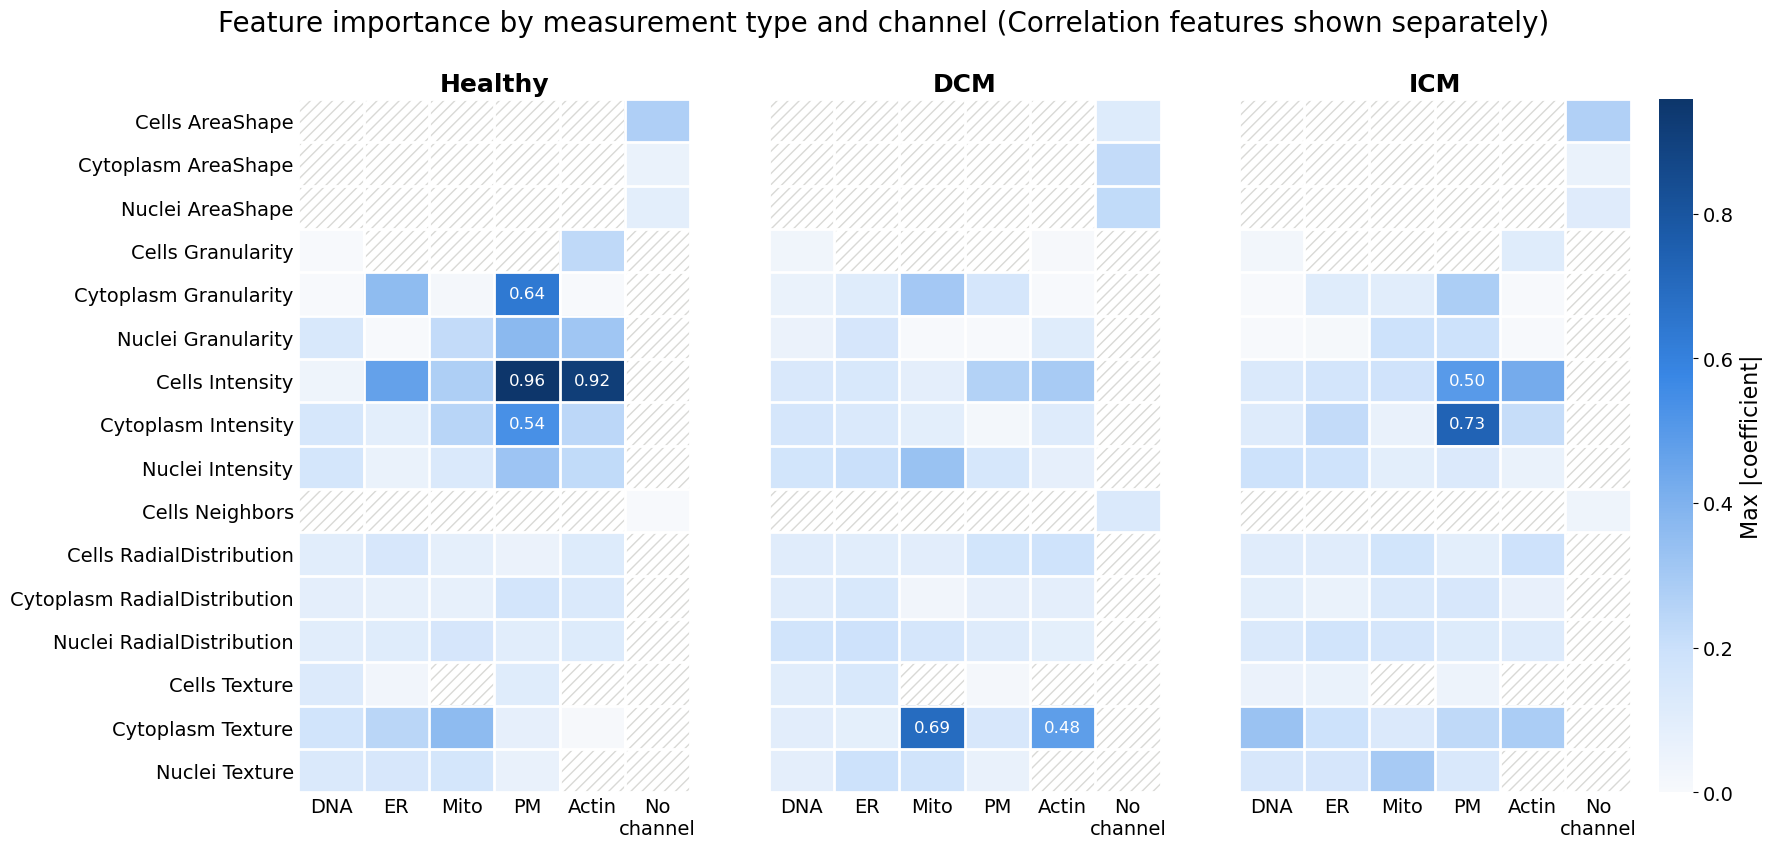

In [5]:
# Shared max of the color scale for all heatmaps
vmax = coefs_df["Abs_Coefficient"].max()

fig = plot_feature_type_heatmaps(
    coefs_df=coefs_df,
    class_order=class_order,
    channels=channels,
    cmap=importance_cmap,
    vmax=vmax,
)
fig.savefig(
    figure_dir / "multiclass_feature_importance_heatmap.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

## Plot the importance of the correlation features per channel pair

Each cell is the max |coefficient| across the compartments and correlation measurements (Correlation, K, Overlap, etc.) for that pair of channels.

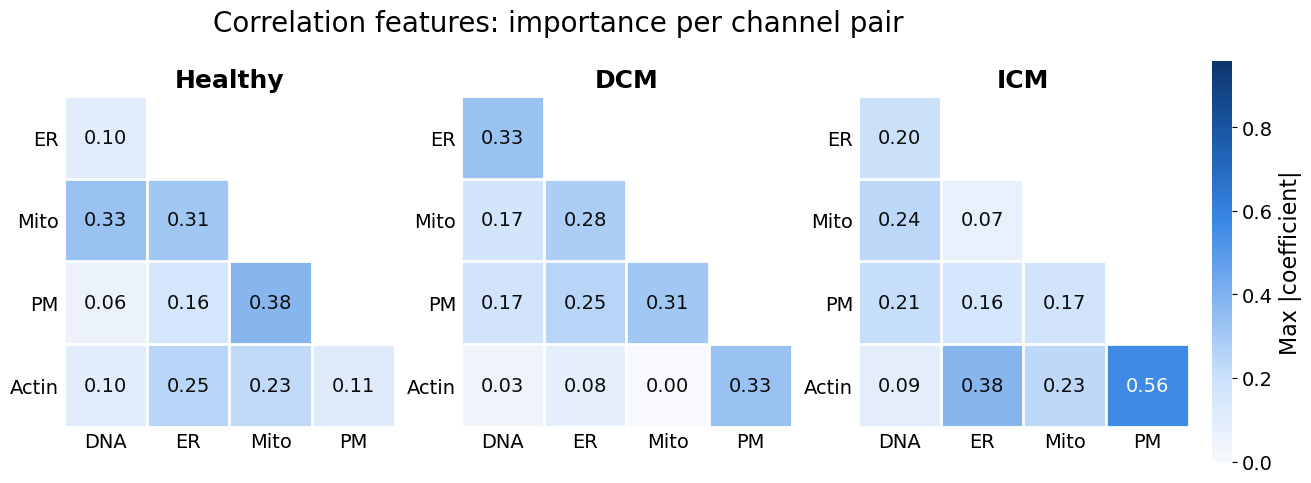

In [6]:
fig = plot_correlation_heatmaps(
    coefs_df=coefs_df,
    class_order=class_order,
    channels=channels,
    cmap=importance_cmap,
    vmax=vmax,
)
fig.savefig(
    figure_dir / "multiclass_correlation_channel_pairs.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

In [7]:
# Show the strongest correlation feature per channel pair and class
corr_df = coefs_df[coefs_df["Feature_Type"] == "Correlation"].copy()
corr_df["Class"] = pd.Categorical(corr_df["Class"], categories=class_order, ordered=True)
corr_df["Channel_Pair"] = [
    " - ".join(sorted(pair, key=channels.index))
    for pair in zip(corr_df["Channel"], corr_df["Channel_2"])
]
top_corr_df = (
    corr_df.loc[corr_df.groupby(["Class", "Channel_Pair"], observed=True)["Abs_Coefficient"].idxmax()]
    .sort_values(["Class", "Abs_Coefficient"], ascending=[True, False])
    .groupby("Class", observed=True)
    .head(3)[["Class", "Channel_Pair", "Feature", "Coefficient"]]
    .reset_index(drop=True)
)
display(top_corr_df)

,Class,Channel_Pair,Feature,Coefficient
0,Healthy,Mito - PM,Nuclei_Correlation_K_Mito_PM,0.381296
1,Healthy,DNA - Mito,Nuclei_Correlation_K_Mito_DNA,0.332034
2,Healthy,ER - Mito,Nuclei_Correlation_K_Mito_ER,0.308205
3,DCM,PM - Actin,Nuclei_Correlation_K_Actin_PM,0.329456
4,DCM,DNA - ER,Cells_Correlation_Correlation_DNA_ER,0.327716
5,DCM,Mito - PM,Cytoplasm_Correlation_Correlation_Mito_PM,-0.309457
6,ICM,PM - Actin,Nuclei_Correlation_K_Actin_PM,-0.558296
7,ICM,ER - Actin,Nuclei_Correlation_K_Actin_ER,-0.381610
8,ICM,DNA - Mito,Cells_Correlation_Correlation_DNA_Mito,0.236296


## Plot the top features per class

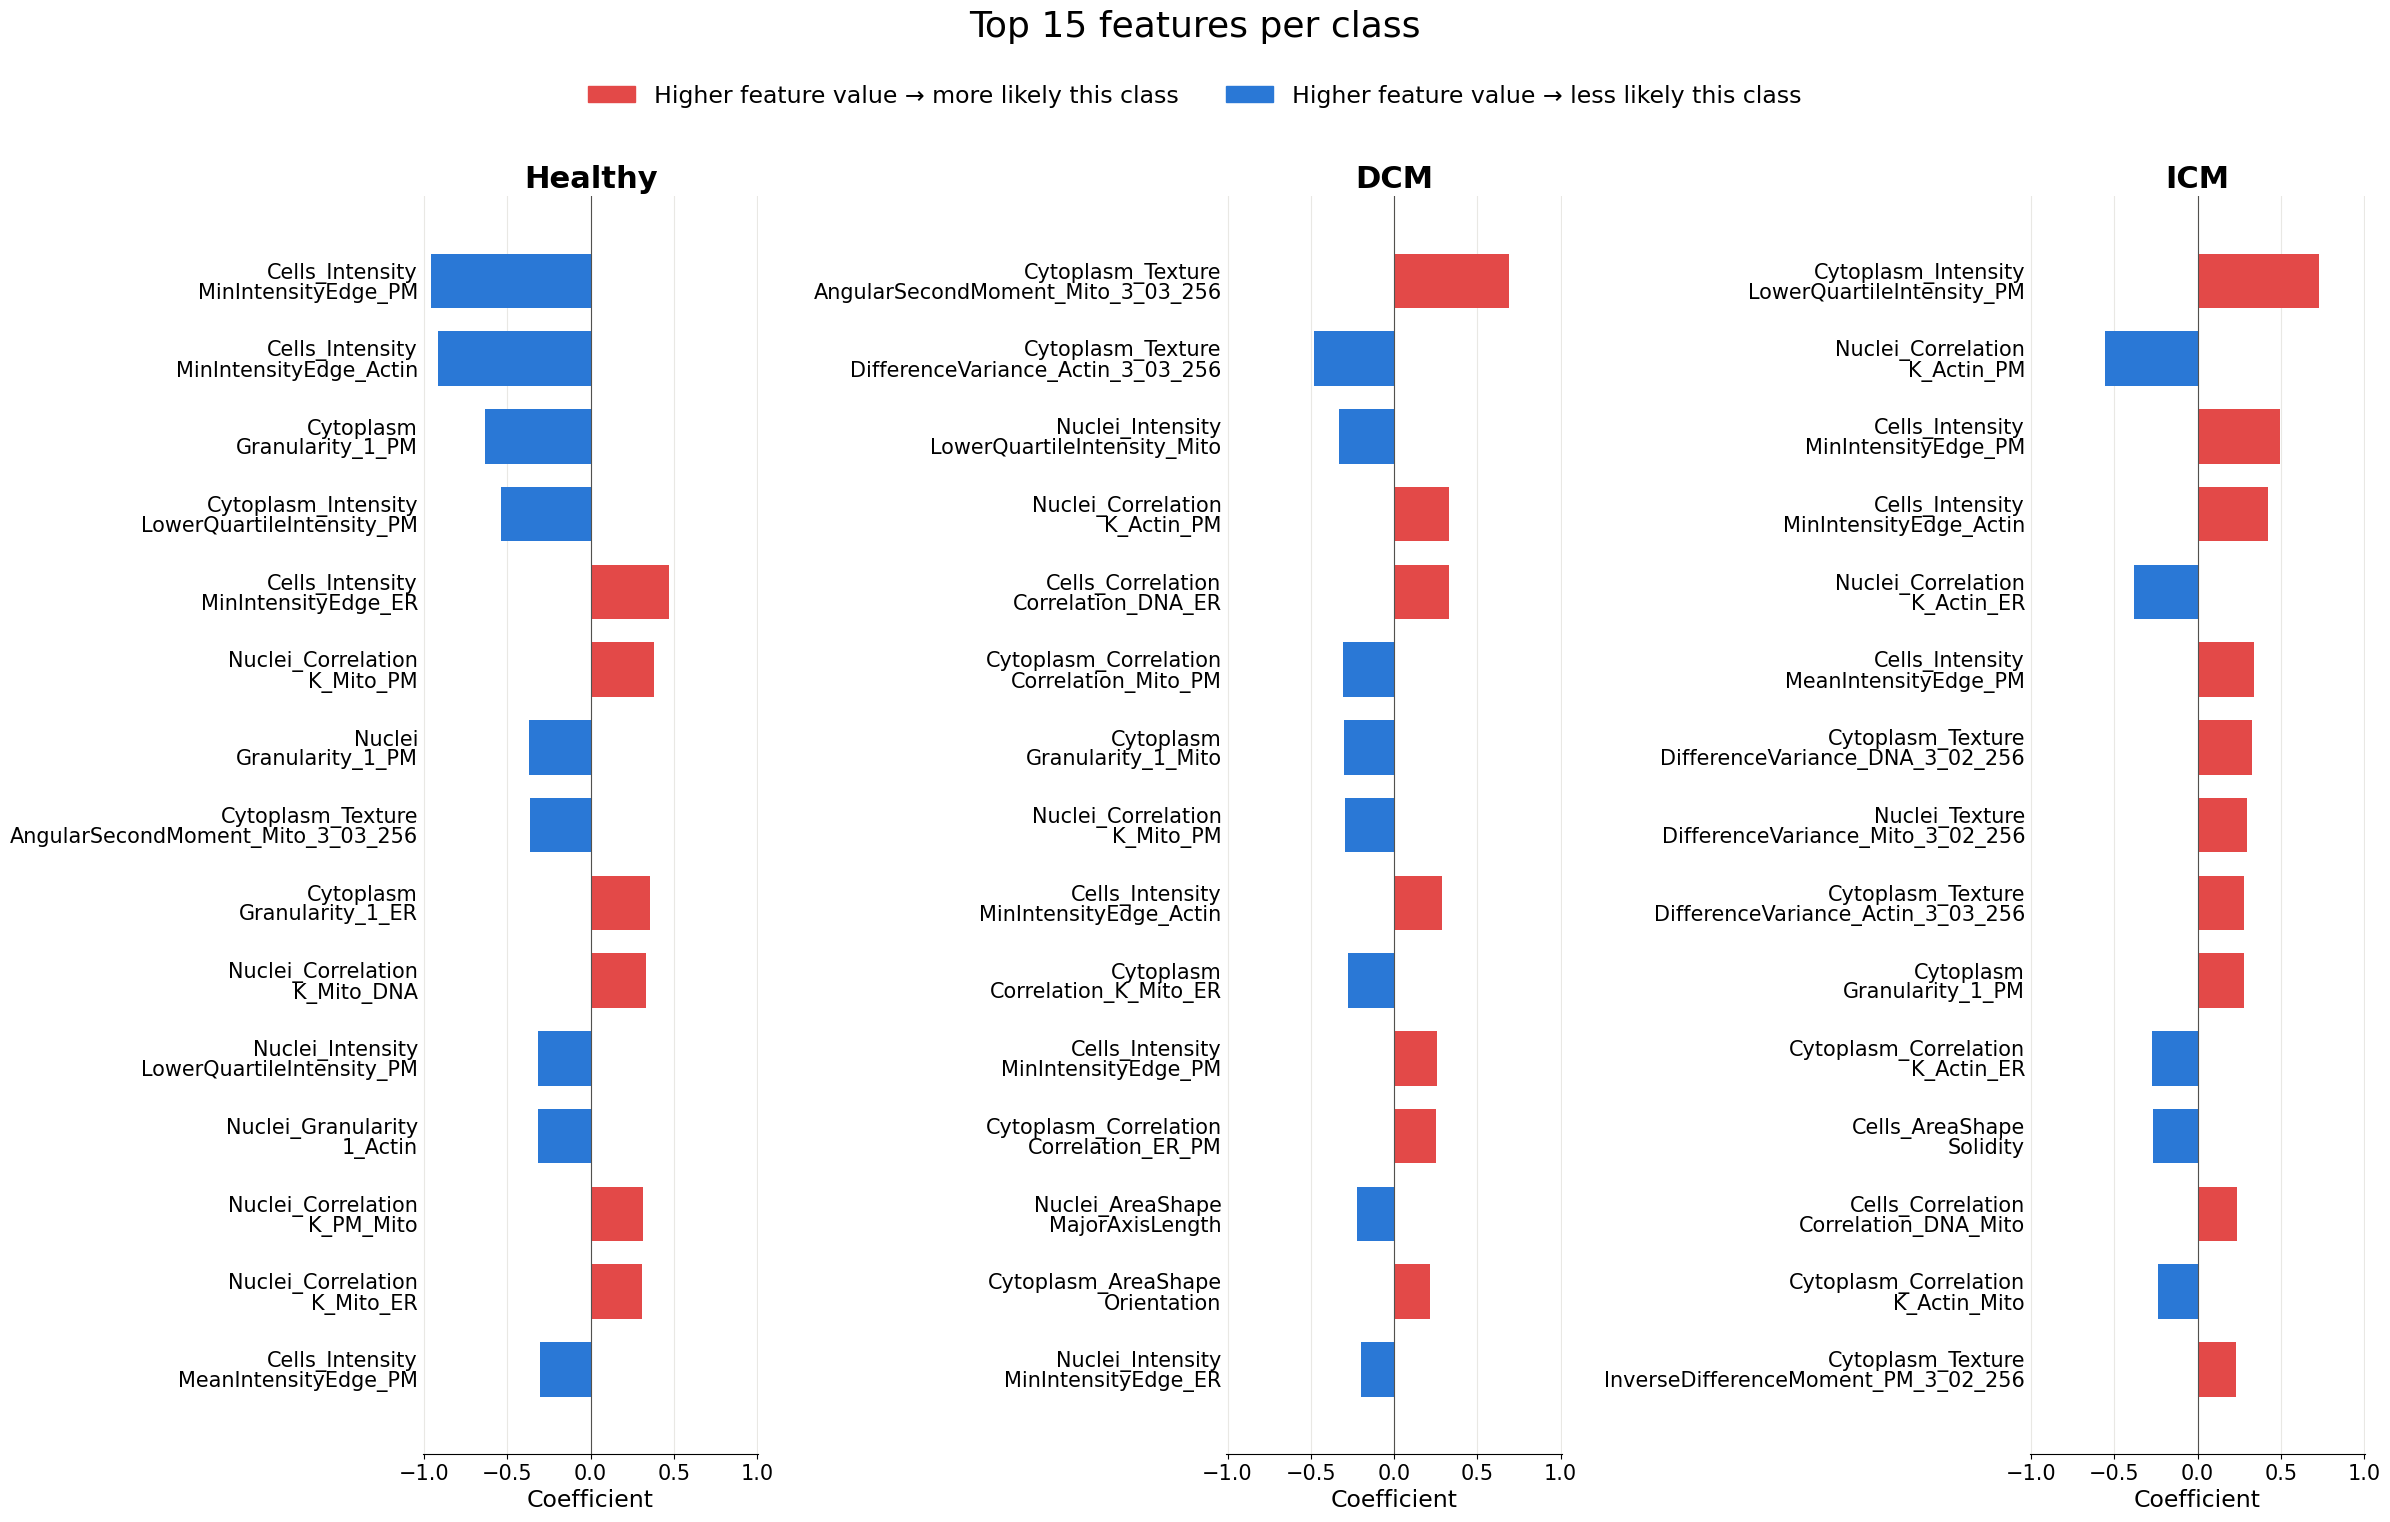

In [8]:
fig = plot_top_features(
    coefs_df=coefs_df,
    class_order=class_order,
    n_top=15,
    pos_color=pos_color,
    neg_color=neg_color,
)
fig.savefig(
    figure_dir / "multiclass_top_features.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()